# JS06 – Regresi: Tugas Praktikum
## Multiple Linear Regression dan SVR pada Medical Cost Personal Dataset

**Tujuan**

1. Mengidentifikasi fitur dan target pada dataset biaya medis.
2. Melakukan eksplorasi data dan penanganan variabel kategorikal.
3. Membangun model **multiple linear regression** dengan `scikit-learn`.
4. Mengevaluasi model dengan **R², MSE, RMSE, dan MAE**.
5. Membandingkan performa regresi linier berganda dengan **SVR** sebagai model non-linear.

**Dataset:** `insurance.csv` berisi 1.338 baris data peserta asuransi. Setelah satu baris duplikat identik dihapus, data yang dianalisis berjumlah **1.337 baris**. Kolom yang tersedia:

| Kolom | Jenis | Keterangan |
|---|---|---|
| `age` | numerik | Usia peserta (tahun) |
| `sex` | kategorikal | Jenis kelamin (`female`, `male`) |
| `bmi` | numerik | Body Mass Index |
| `children` | numerik | Jumlah anak/tanggungan |
| `smoker` | kategorikal | Status merokok (`yes`, `no`) |
| `region` | kategorikal | Wilayah tempat tinggal di Amerika Serikat |
| `charges` | numerik | **Target**: biaya medis tahunan (USD) |

Tujuan tugas ini adalah memprediksi `charges` berdasarkan fitur-fitur lainnya.

### 0. Import library

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 50)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Membaca dan memahami data

In [2]:
df = pd.read_csv("insurance.csv")

print("Ukuran data:", df.shape)
df.head()

Ukuran data: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [5]:
print("Nilai kosong per kolom:")
print(df.isna().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())
print("\nNilai unik variabel kategorikal:")
for col in ["sex", "smoker", "region"]:
    print(f"{col:8s}: {df[col].unique()}")

Nilai kosong per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah baris duplikat: 1

Nilai unik variabel kategorikal:
sex     : <StringArray>
['female', 'male']
Length: 2, dtype: str
smoker  : <StringArray>
['yes', 'no']
Length: 2, dtype: str
region  : <StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [6]:
print("Sebelum deduplikasi:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("Setelah deduplikasi:", df.shape)

Sebelum deduplikasi: (1338, 7)
Setelah deduplikasi: (1337, 7)


Satu baris duplikat identik ditemukan dan dihapus agar tidak memberikan bobot ganda pada proses pelatihan. Setelah deduplikasi, tersisa **1.337 baris**. Tidak ada nilai kosong, sehingga tidak diperlukan imputasi.

### 2. Eksplorasi data (EDA)

Distribusi target `charges` penting diperiksa karena regresi linier mengasumsikan error yang kira-kira normal dan variansi konstan. Kita juga melihat hubungan `charges` dengan `age`, `bmi`, dan status merokok.

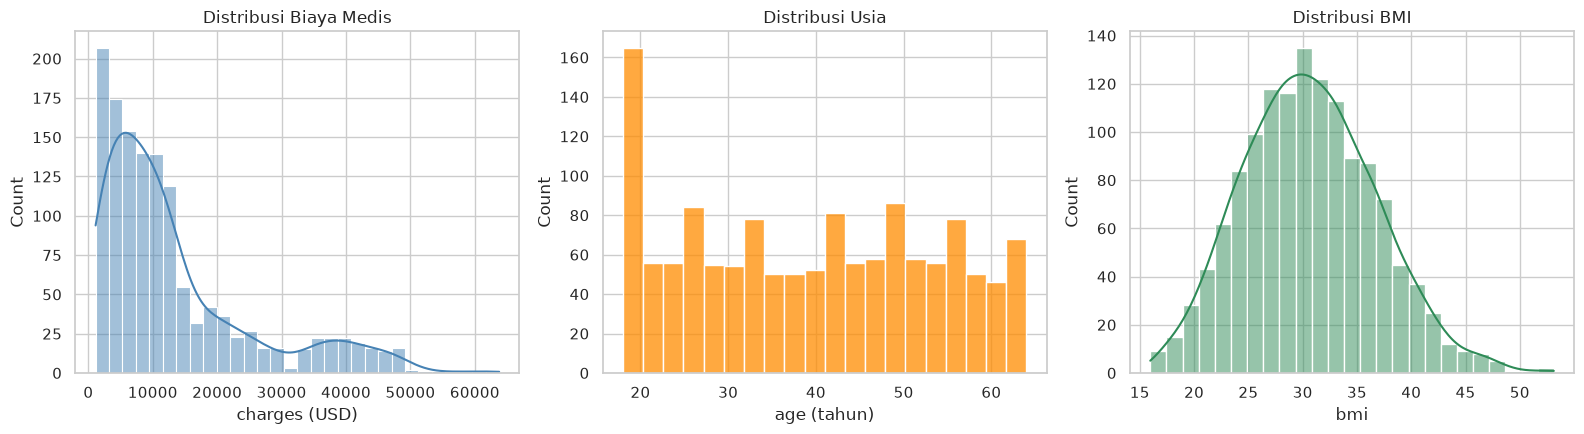

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df["charges"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Biaya Medis")
axes[0].set_xlabel("charges (USD)")

sns.histplot(df["age"], bins=20, ax=axes[1], color="darkorange")
axes[1].set_title("Distribusi Usia")
axes[1].set_xlabel("age (tahun)")

sns.histplot(df["bmi"], bins=25, kde=True, ax=axes[2], color="seagreen")
axes[2].set_title("Distribusi BMI")
axes[2].set_xlabel("bmi")

plt.tight_layout()
plt.show()

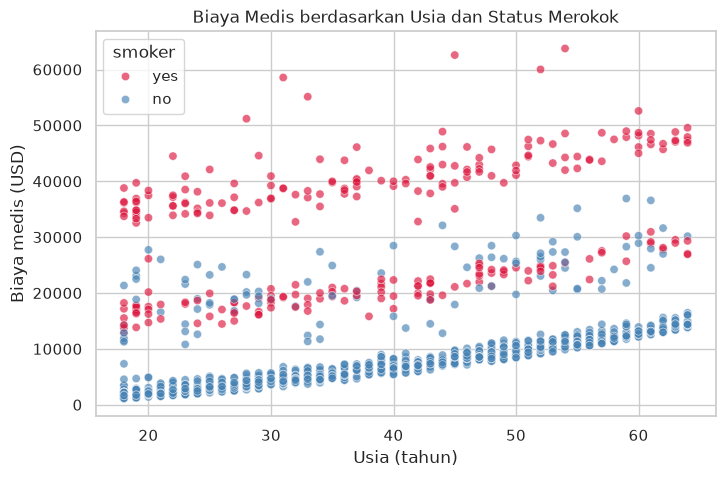

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker",
    palette={"yes": "crimson", "no": "steelblue"},
    alpha=0.65,
)
plt.title("Biaya Medis berdasarkan Usia dan Status Merokok")
plt.xlabel("Usia (tahun)")
plt.ylabel("Biaya medis (USD)")
plt.show()

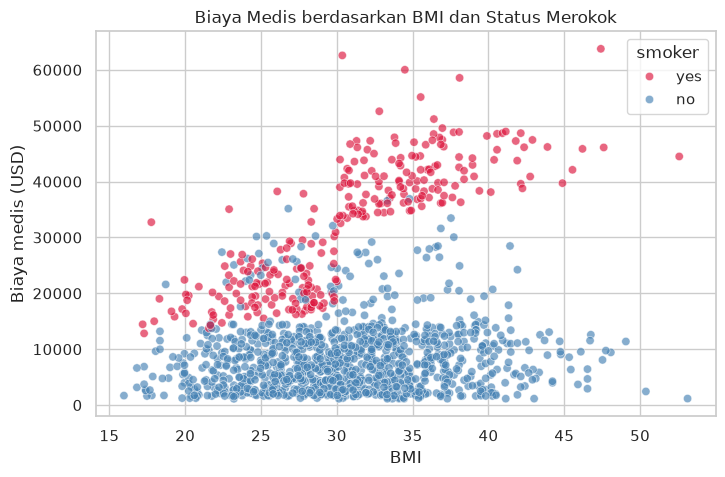

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker",
    palette={"yes": "crimson", "no": "steelblue"},
    alpha=0.65,
)
plt.title("Biaya Medis berdasarkan BMI dan Status Merokok")
plt.xlabel("BMI")
plt.ylabel("Biaya medis (USD)")
plt.show()

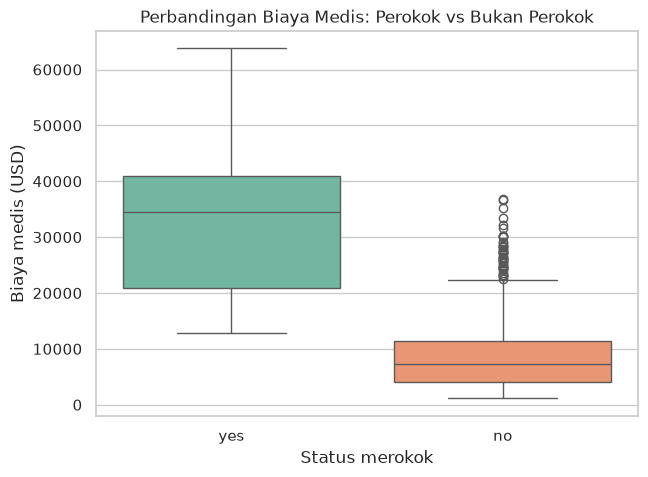

,count,mean,median,std
smoker,,,,
no,1063,8440.66,7345.73,5992.97
yes,274,32050.23,34456.35,11541.55


In [10]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="smoker", y="charges", hue="smoker", palette="Set2", legend=False)
plt.title("Perbandingan Biaya Medis: Perokok vs Bukan Perokok")
plt.xlabel("Status merokok")
plt.ylabel("Biaya medis (USD)")
plt.show()

df.groupby("smoker")["charges"].agg(["count", "mean", "median", "std"]).round(2)

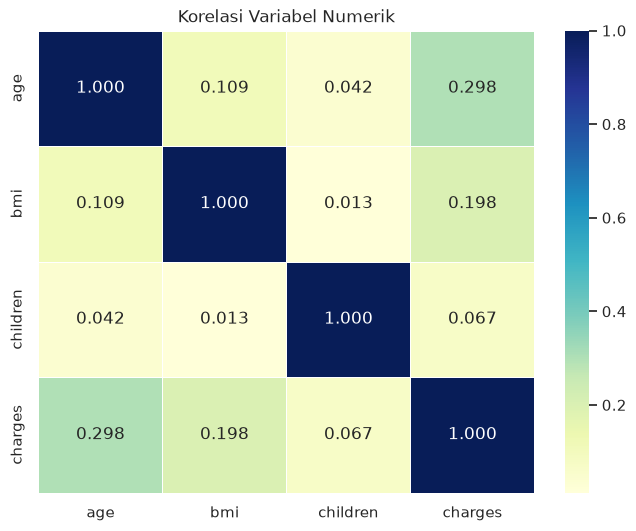

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap="YlGnBu",
    annot=True,
    fmt=".3f",
    linewidths=0.5,
)
plt.title("Korelasi Variabel Numerik")
plt.show()

**Temuan EDA.** Distribusi `charges` menceng ke kanan: sebagian besar peserta memiliki biaya relatif rendah, tetapi ada sejumlah kecil peserta dengan biaya sangat tinggi. Perokok memiliki biaya medis yang jauh lebih tinggi daripada bukan perokok. Usia dan BMI juga menunjukkan hubungan positif dengan biaya, terutama pada kelompok perokok. Pola ini menunjukkan bahwa interaksi antarfitur kemungkinan penting, sehingga model linear sederhana mungkin belum menangkap seluruh struktur data.

### 3. Praproses data

Langkah praproses:

1. Hapus satu baris duplikat identik yang ditemukan pada tahap pemeriksaan kualitas data.
2. Pisahkan target `charges` dari fitur.
3. Ubah variabel kategorikal (`sex`, `smoker`, `region`) menjadi **one-hot encoding** dengan `pd.get_dummies(..., drop_first=True)` untuk menghindari multikolinearitas sempurna (*dummy variable trap*).
4. Bagi data menjadi **80% data latih** dan **20% data uji** dengan `random_state=42`.
5. Untuk regresi linier berganda, scaling **tidak wajib** karena koefisien OLS tidak berubah secara substantif dan tetap dapat ditafsirkan dalam satuan asli. Scaling dilakukan terpisah untuk SVR yang berbasis jarak.

Tidak ada nilai kosong pada dataset, sehingga tidak diperlukan imputasi.

In [12]:
X = pd.get_dummies(df.drop(columns="charges"), drop_first=True).astype(float)
y = df["charges"].to_numpy()

print("Fitur setelah encoding:")
print(list(X.columns))
print("\nUkuran X:", X.shape)
X.head()

Fitur setelah encoding:
['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

Ukuran X: (1337, 8)


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19.0,27.900,0.0,0.0,1.0,0.0,0.0,1.0
1,18.0,33.770,1.0,1.0,0.0,0.0,1.0,0.0
2,28.0,33.000,3.0,1.0,0.0,0.0,1.0,0.0
3,33.0,22.705,0.0,1.0,0.0,1.0,0.0,0.0
4,32.0,28.880,0.0,1.0,0.0,1.0,0.0,0.0


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print("Data latih :", X_train.shape)
print("Data uji   :", X_test.shape)

Data latih : (1069, 8)
Data uji   : (268, 8)


### 4. Multiple linear regression

Model regresi linier berganda:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots + \beta_p x_p.$$

Model dilatih dengan `LinearRegression` dari `scikit-learn` menggunakan data latih, lalu digunakan untuk memprediksi data uji.

In [14]:
model_mlr = LinearRegression()
model_mlr.fit(X_train, y_train)

y_pred_mlr = model_mlr.predict(X_test)

print("Intersep:", round(model_mlr.intercept_, 2))
print("Jumlah koefisien:", len(model_mlr.coef_))

Intersep: -11092.65
Jumlah koefisien: 8


In [15]:
koefisien = pd.DataFrame({
    "Fitur": X.columns,
    "Koefisien (USD per satuan)": model_mlr.coef_,
})
koefisien["Pengaruh absolut"] = koefisien["Koefisien (USD per satuan)"].abs()
koefisien = koefisien.sort_values("Pengaruh absolut", ascending=False).drop(columns="Pengaruh absolut")
koefisien.round(2)

,Fitur,Koefisien (USD per satuan)
4,smoker_yes,23077.76
6,region_southeast,-838.92
7,region_southwest,-659.14
2,children,533.01
5,region_northwest,-391.76
1,bmi,318.70
0,age,248.21
3,sex_male,-101.54


**Cara membaca koefisien.** Karena fitur numerik tidak diskalakan, koefisien menyatakan perubahan prediksi `charges` (USD) untuk kenaikan satu satuan fitur, dengan asumsi fitur lain tetap. Koefisien variabel dummy menyatakan selisih relatif terhadap kategori acuan (`sex_female`, `smoker_no`, `region_northeast`).

### 5. Evaluasi multiple linear regression

In [16]:
mse_mlr = mean_squared_error(y_test, y_pred_mlr)
rmse_mlr = np.sqrt(mse_mlr)
mae_mlr = mean_absolute_error(y_test, y_pred_mlr)
r2_mlr = r2_score(y_test, y_pred_mlr)

evaluasi_mlr = pd.DataFrame({
    "Metrik": ["R²", "MSE (USD²)", "RMSE (USD)", "MAE (USD)"],
    "Nilai": [r2_mlr, mse_mlr, rmse_mlr, mae_mlr],
})
evaluasi_mlr["Nilai"] = evaluasi_mlr["Nilai"].map(lambda v: f"{v:,.4f}")
evaluasi_mlr

,Metrik,Nilai
0,R²,0.8069
1,MSE (USD²),"35,478,020.6752"
2,RMSE (USD),"5,956.3429"
3,MAE (USD),"4,177.0456"


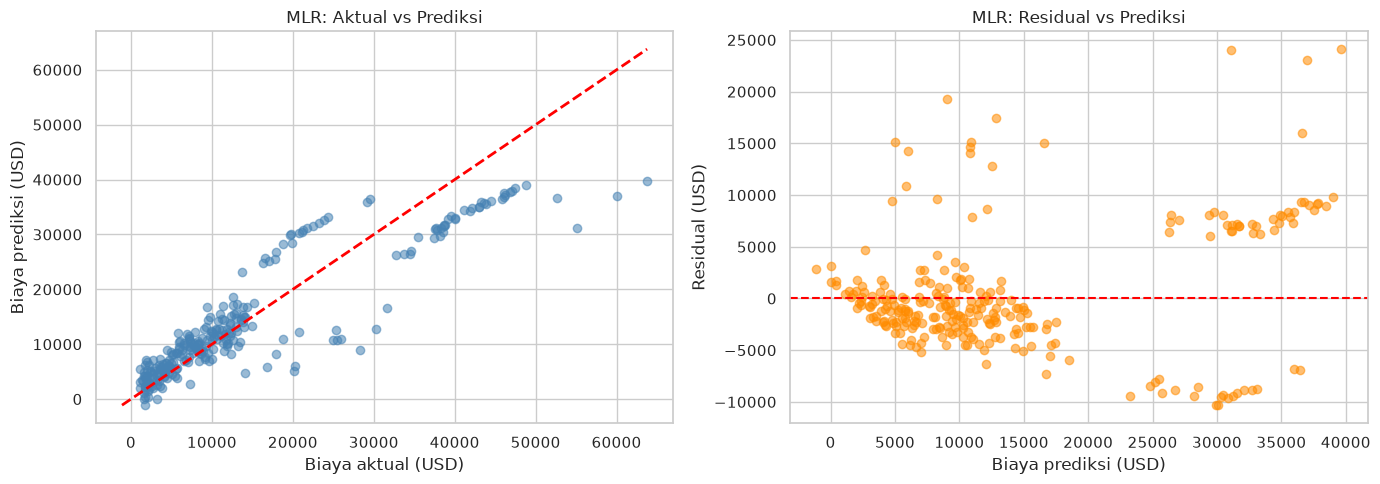

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_mlr, alpha=0.55, color="steelblue")
batas = [min(y_test.min(), y_pred_mlr.min()), max(y_test.max(), y_pred_mlr.max())]
axes[0].plot(batas, batas, color="red", linestyle="--", linewidth=2)
axes[0].set_title("MLR: Aktual vs Prediksi")
axes[0].set_xlabel("Biaya aktual (USD)")
axes[0].set_ylabel("Biaya prediksi (USD)")

residual_mlr = y_test - y_pred_mlr
axes[1].scatter(y_pred_mlr, residual_mlr, alpha=0.55, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("MLR: Residual vs Prediksi")
axes[1].set_xlabel("Biaya prediksi (USD)")
axes[1].set_ylabel("Residual (USD)")

plt.tight_layout()
plt.show()

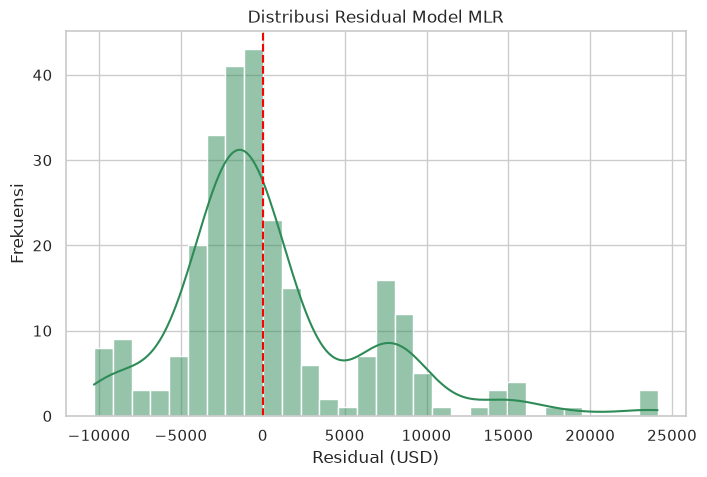

Rata-rata residual : 425.26
Simpangan baku     : 5941.14


In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(residual_mlr, bins=30, kde=True, color="seagreen")
plt.axvline(0, color="red", linestyle="--", linewidth=1.5)
plt.title("Distribusi Residual Model MLR")
plt.xlabel("Residual (USD)")
plt.ylabel("Frekuensi")
plt.show()

print("Rata-rata residual :", round(residual_mlr.mean(), 2))
print("Simpangan baku     :", round(residual_mlr.std(), 2))

### 6. Pembanding: Support Vector Regression (SVR)

SVR dengan kernel RBF dipakai sebagai pembanding non-linear. Karena SVR sensitif terhadap skala, fitur **dan** target diskalakan menggunakan `StandardScaler` yang di-fit hanya pada data latih. Parameter `C`, `gamma`, dan `epsilon` dipilih dengan `GridSearchCV` (3-fold) pada data latih, kemudian model terbaik diuji pada data uji.

In [19]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()

param_grid = {
    "C": [1, 10, 100],
    "gamma": [0.01, 0.05, 0.1],
    "epsilon": [0.05, 0.1, 0.2],
}

grid_svr = GridSearchCV(
    estimator=SVR(kernel="rbf"),
    param_grid=param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1,
)
grid_svr.fit(X_train_scaled, y_train_scaled)

print("Parameter terbaik :", grid_svr.best_params_)
print("R² validasi silang:", round(grid_svr.best_score_, 4))

Parameter terbaik : {'C': 100, 'epsilon': 0.1, 'gamma': 0.01}
R² validasi silang: 0.8227


In [20]:
model_svr = grid_svr.best_estimator_

y_pred_svr_scaled = model_svr.predict(X_test_scaled)
y_pred_svr = scaler_y.inverse_transform(y_pred_svr_scaled.reshape(-1, 1)).ravel()

mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
mae_svr = mean_absolute_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)

evaluasi_svr = pd.DataFrame({
    "Metrik": ["R²", "MSE (USD²)", "RMSE (USD)", "MAE (USD)"],
    "Nilai": [r2_svr, mse_svr, rmse_svr, mae_svr],
})
evaluasi_svr["Nilai"] = evaluasi_svr["Nilai"].map(lambda v: f"{v:,.4f}")
evaluasi_svr

,Metrik,Nilai
0,R²,0.8862
1,MSE (USD²),"20,919,809.2290"
2,RMSE (USD),"4,573.8178"
3,MAE (USD),"2,553.1730"


In [21]:
perbandingan = pd.DataFrame({
    "Model": ["Multiple Linear Regression", "SVR (RBF, tuned)"],
    "R²": [r2_mlr, r2_svr],
    "RMSE (USD)": [rmse_mlr, rmse_svr],
    "MAE (USD)": [mae_mlr, mae_svr],
})
perbandingan.round(2)

,Model,R²,RMSE (USD),MAE (USD)
0,Multiple Linear Regression,0.81,5956.34,4177.05
1,"SVR (RBF, tuned)",0.89,4573.82,2553.17


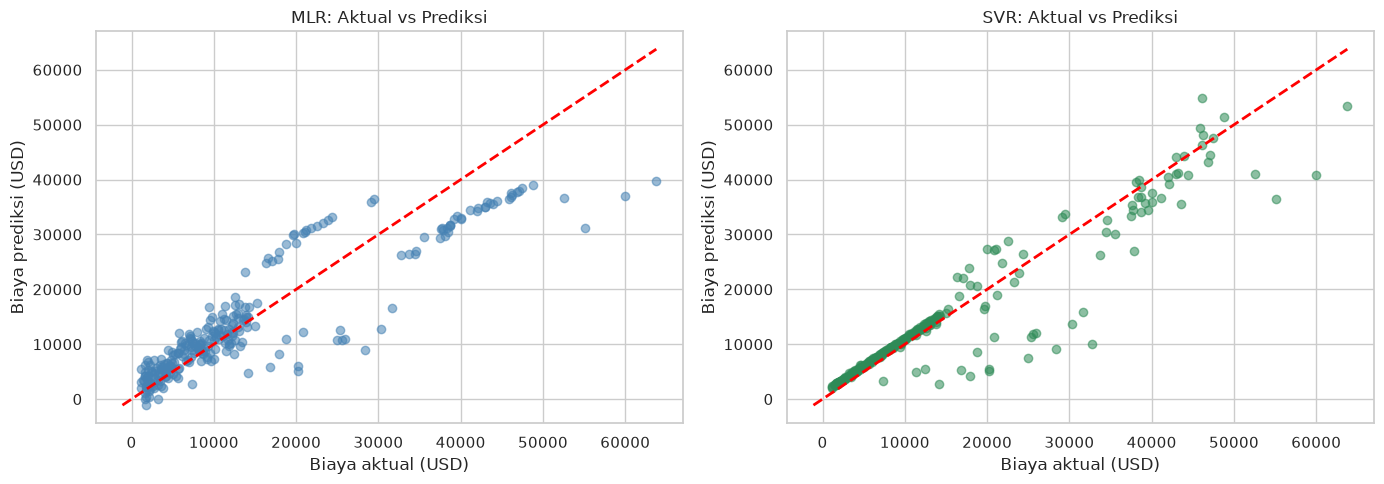

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_mlr, alpha=0.55, color="steelblue")
axes[0].plot(batas, batas, color="red", linestyle="--", linewidth=2)
axes[0].set_title("MLR: Aktual vs Prediksi")
axes[0].set_xlabel("Biaya aktual (USD)")
axes[0].set_ylabel("Biaya prediksi (USD)")

axes[1].scatter(y_test, y_pred_svr, alpha=0.55, color="seagreen")
axes[1].plot(batas, batas, color="red", linestyle="--", linewidth=2)
axes[1].set_title("SVR: Aktual vs Prediksi")
axes[1].set_xlabel("Biaya aktual (USD)")
axes[1].set_ylabel("Biaya prediksi (USD)")

plt.tight_layout()
plt.show()

### 7. Analisis hasil

**Multiple linear regression**

- R² data uji sekitar **0,807**, artinya model menjelaskan sekitar **80,7%** variansi biaya medis.
- RMSE sekitar **5.956 USD** dan MAE sekitar **4.177 USD**. Rata-rata error absolut sekitar 4 ribu USD masih cukup besar dibandingkan median biaya medis, sehingga prediksi per individu perlu ditafsirkan dengan hati-hati.
- Koefisien terbesar berasal dari `smoker_yes`: perokok diprediksi memiliki biaya sekitar **23.078 USD lebih tinggi** daripada bukan perokok dengan fitur lain dianggap sama.
- `age` menambah sekitar **248 USD per tahun**, `bmi` sekitar **319 USD per poin BMI**, dan `children` sekitar **533 USD per anak**.
- Koefisien `sex_male` dan variabel wilayah relatif kecil, menunjukkan kontribusinya lebih lemah setelah variabel lain diperhitungkan.

**SVR**

- SVR dengan parameter terbaik dari validasi silang (`C=100`, `gamma=0,01`, `epsilon=0,1`) menghasilkan R² data uji sekitar **0,886**, RMSE sekitar **4.574 USD**, dan MAE sekitar **2.553 USD**.
- SVR lebih baik daripada MLR pada ketiga metrik. Hal ini masuk akal karena SVR RBF dapat menangkap hubungan non-linear dan interaksi antarfitur, misalnya efek BMI yang berbeda pada perokok dan bukan perokok.
- Peningkatan R² dari 0,807 menjadi 0,886 menunjukkan bahwa masih ada struktur non-linear yang tidak tertangkap oleh model linear.

**Keterbatasan**

- Dataset hanya 1.337 baris setelah deduplikasi; hasil dapat berubah pada pembagian data yang berbeda.
- `charges` menceng ke kanan dan memiliki outlier. Transformasi logaritmik pada target atau model berbasis pohon dapat menjadi alternatif.
- Korelasi dan koefisien tidak membuktikan kausalitas.
- Pemilihan hiperparameter SVR dilakukan pada data latih, tetapi satu pembagian data uji masih memberikan estimasi yang berfluktuasi.

### 8. Kesimpulan

1. Variabel target adalah `charges`; fitur yang dipakai adalah `age`, `sex`, `bmi`, `children`, `smoker`, dan `region` yang telah di-one-hot encoding.
2. Multiple linear regression dengan `scikit-learn` menghasilkan R² data uji ≈ **0,807**, RMSE ≈ **5.956 USD**, dan MAE ≈ **4.177 USD**.
3. Status merokok adalah prediktor terkuat, diikuti usia dan BMI.
4. SVR RBF yang diskalakan dan di-tuning memberikan performa lebih baik: R² ≈ **0,886**, RMSE ≈ **4.574 USD**, dan MAE ≈ **2.553 USD**.
5. Secara keseluruhan, hubungan biaya medis dengan fitur-fitur peserta bersifat non-linear dan dipengaruhi interaksi antarfitur, sehingga model non-linear seperti SVR lebih sesuai daripada regresi linier saja.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS06 – Regresi, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-regresi
- Lantz, B. (2019). *Machine Learning with R* (3rd ed.). Packt Publishing. (Dataset Medical Cost Personal)
- `scikit-learn` – Linear Regression. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
- `scikit-learn` – Support Vector Regression dan GridSearchCV. https://scikit-learn.org/stable/modules/grid_search.html
- `scikit-learn` – Regression Metrics. https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics